In [ ]:
from google.colab import auth
auth.authenticate_user()

In [ ]:
import google.auth

credentials, project = google.auth.default()

print("Authentication successful!")

Authentication successful!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

os.listdir('/content/drive/MyDrive')

['Colab Notebooks',
 'adhar ramya',
 'ramya',
 'ramya adhar',
 'Nurturing Digital Intelligence in schools .gform',
 'Untitled form (1).gform',
 'Untitled form.gform',
 'IMG-20251129-WA0011.jpg',
 'ramya inter.pdf',
 'ramya 10th.pdf',
 '1-0079d012-400f-4e33-a754-827bb95f594f (1) (1).pdf',
 '1-0079d012-400f-4e33-a754-827bb95f594f (1).pdf',
 'Ramya_Sri_Resume.pdf',
 'Ramya_I_Resume-1.pdf',
 'Ramya_I_Resume (2).pdf',
 '68461a86-2ec1-4e9d-a4a6-0029904b3a81.tmp',
 'Ramya_IBM_Resume.pdf',
 'Solar_Panel_Project.']

In [ ]:
import os

drive_path = '/content/drive/MyDrive'

for root, dirs, files in os.walk(drive_path):
    for file in files:
        if 'hotspot' in file.lower() and file.endswith('.zip'):
            print("Dataset found:", os.path.join(root, file))

Dataset found: /content/drive/MyDrive/Solar_Panel_Project./hotspot_dataset_yolo.zip


In [ ]:
import zipfile
import os

zip_path = '/content/drive/MyDrive/Solar_Panel_Project./hotspot_dataset_yolo.zip'

extract_path = '/content/drive/MyDrive/Solar_Panel_Project./hotspot_dataset'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
import os

for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, '').count(os.sep)
    print('  ' * level + os.path.basename(root) + '/')
    if level >= 2:
        dirs[:] = []

hotspot_dataset/
  hotspot_dataset_yolo/
    test/
    train/
    valid/


In [ ]:
import os

dataset_path = os.path.join(extract_path, 'hotspot_dataset_yolo')

for root, dirs, files in os.walk(dataset_path):
    print("\nFolder:", root)
    print("Files:", files[:10])


Folder: /content/drive/MyDrive/Solar_Panel_Project./hotspot_dataset/hotspot_dataset_yolo
Files: []

Folder: /content/drive/MyDrive/Solar_Panel_Project./hotspot_dataset/hotspot_dataset_yolo/test
Files: []

Folder: /content/drive/MyDrive/Solar_Panel_Project./hotspot_dataset/hotspot_dataset_yolo/test/images
Files: ['Sample_09_aug_001.png', 'Sample_09_aug_002.png', 'Sample_09_aug_003.png', 'Sample_09_aug_004.png', 'Sample_09_aug_005.png', 'Sample_09_aug_006.png', 'Sample_09_aug_007.png', 'Sample_09_aug_008.png', 'Sample_09_aug_009.png', 'Sample_09_aug_010.png']

Folder: /content/drive/MyDrive/Solar_Panel_Project./hotspot_dataset/hotspot_dataset_yolo/train
Files: []

Folder: /content/drive/MyDrive/Solar_Panel_Project./hotspot_dataset/hotspot_dataset_yolo/train/images
Files: ['Sample_01_aug_001.png', 'Sample_01_aug_002.png', 'Sample_01_aug_003.png', 'Sample_01_aug_004.png', 'Sample_01_aug_005.png', 'Sample_01_aug_006.png', 'Sample_01_aug_007.png', 'Sample_01_aug_008.png', 'Sample_01_aug_009

In [ ]:
import os

dataset_path = os.path.join(extract_path, 'hotspot_dataset_yolo')

for split in ['train', 'valid', 'test']:
    image_path = os.path.join(dataset_path, split, 'images')
    label_path = os.path.join(dataset_path, split, 'labels')

    print("\n", split.upper())
    print("Images:", len(os.listdir(image_path)))
    print("Labels folder exists:", os.path.exists(label_path))

    if os.path.exists(label_path):
        print("Label files:", len(os.listdir(label_path)))

print("\ndata.yaml exists:",
      os.path.exists(os.path.join(dataset_path, 'data.yaml')))


 TRAIN
Images: 4000
Labels folder exists: False

 VALID
Images: 500
Labels folder exists: False

 TEST
Images: 500
Labels folder exists: False

data.yaml exists: False


In [ ]:
import zipfile

zip_path = '/content/drive/MyDrive/Solar_Panel_Project./hotspot_dataset_yolo.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    for name in zip_ref.namelist()[:40]:
        print(name)

hotspot_dataset_yolo/
hotspot_dataset_yolo/test/
hotspot_dataset_yolo/test/images/
hotspot_dataset_yolo/test/images/Sample_09_aug_001.png
hotspot_dataset_yolo/test/images/Sample_09_aug_002.png
hotspot_dataset_yolo/test/images/Sample_09_aug_003.png
hotspot_dataset_yolo/test/images/Sample_09_aug_004.png
hotspot_dataset_yolo/test/images/Sample_09_aug_005.png
hotspot_dataset_yolo/test/images/Sample_09_aug_006.png
hotspot_dataset_yolo/test/images/Sample_09_aug_007.png
hotspot_dataset_yolo/test/images/Sample_09_aug_008.png
hotspot_dataset_yolo/test/images/Sample_09_aug_009.png
hotspot_dataset_yolo/test/images/Sample_09_aug_010.png
hotspot_dataset_yolo/test/images/Sample_09_aug_011.png
hotspot_dataset_yolo/test/images/Sample_09_aug_012.png
hotspot_dataset_yolo/test/images/Sample_09_aug_013.png
hotspot_dataset_yolo/test/images/Sample_09_aug_014.png
hotspot_dataset_yolo/test/images/Sample_09_aug_015.png
hotspot_dataset_yolo/test/images/Sample_09_aug_016.png
hotspot_dataset_yolo/test/images/Samp

In [ ]:
import zipfile

zip_path = '/content/drive/MyDrive/Solar_Panel_Project./hotspot_dataset_yolo.zip'

with zipfile.ZipFile(zip_path, 'r') as z:
    names = z.namelist()

    label_files = [n for n in names if '/labels/' in n]
    yaml_files = [n for n in names if n.endswith('.yaml')]

    print("Total files:", len(names))
    print("Label files:", len(label_files))
    print("YAML files:", yaml_files[:10])

Total files: 5007
Label files: 0
YAML files: []


In [ ]:

import zipfile
import os

zip_path = '/content/drive/MyDrive/Solar_Panel_Project./hotspot_dataset_yolo.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    files = [f for f in zip_ref.namelist() if not f.endswith('/')]

    image_extensions = ('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff')

    images = [f for f in files if f.lower().endswith(image_extensions)]
    other_files = [f for f in files if not f.lower().endswith(image_extensions)]

    print("Total files:", len(files))
    print("Image files:", len(images))
    print("Other files:", len(other_files))

    print("\nOther files:")
    for f in other_files[:100]:
        print(f)


Total files: 5000
Image files: 5000
Other files: 0

Other files:


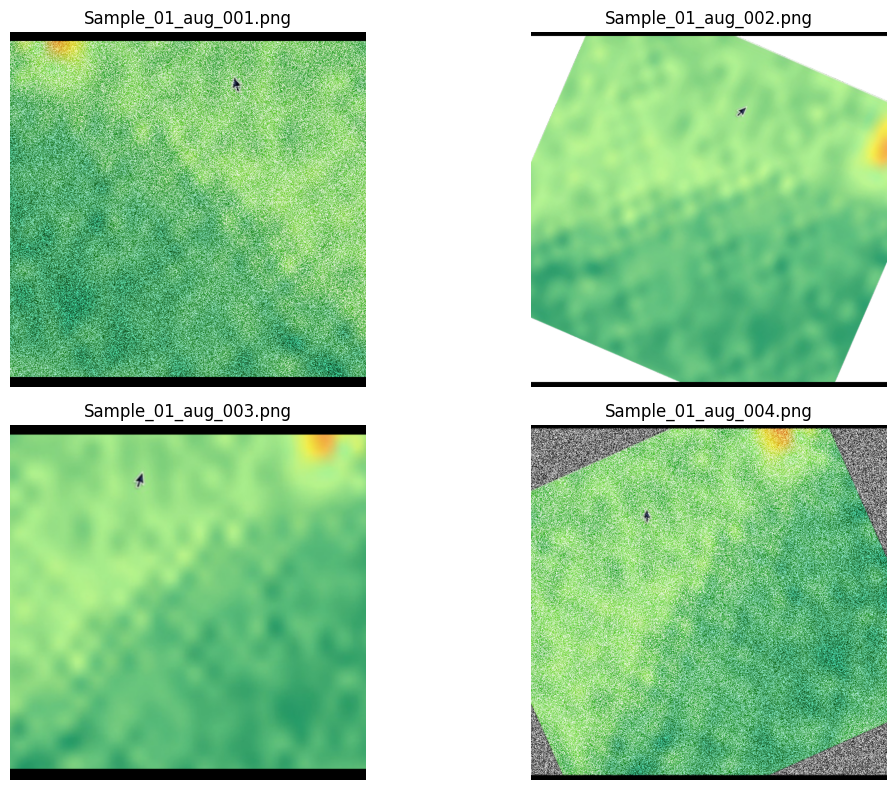

In [ ]:

import os
import matplotlib.pyplot as plt
from PIL import Image

image_folder = os.path.join(dataset_path, 'train', 'images')

image_files = sorted(os.listdir(image_folder))

plt.figure(figsize=(12, 8))

for i in range(4):
    img_path = os.path.join(image_folder, image_files[i])
    img = Image.open(img_path)

    plt.subplot(2, 2, i + 1)
    plt.imshow(img)
    plt.title(image_files[i])
    plt.axis('off')

plt.tight_layout()
plt.show()


In [ ]:

from google.colab import files

uploaded = files.upload()


Saving training_artifacts (1).zip to training_artifacts (1).zip


In [ ]:

import zipfile

zip_path = "training_artifacts (1).zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    files_list = zip_ref.namelist()

    print("Total files:", len(files_list))
    print("\nFiles inside ZIP:")

    for file in files_list:
        print(file)


Total files: 11

Files inside ZIP:
training_artifacts/
training_artifacts/args.yaml (Hotspot).yaml
training_artifacts/BoxF1_curve.png
training_artifacts/BoxPR_curve.png
training_artifacts/BoxP_curve.png
training_artifacts/BoxR_curve.png
training_artifacts/confusion_matrix.png
training_artifacts/confusion_matrix_normalized.png
training_artifacts/labels.jpg
training_artifacts/results (Hotspot).csv
training_artifacts/results.png


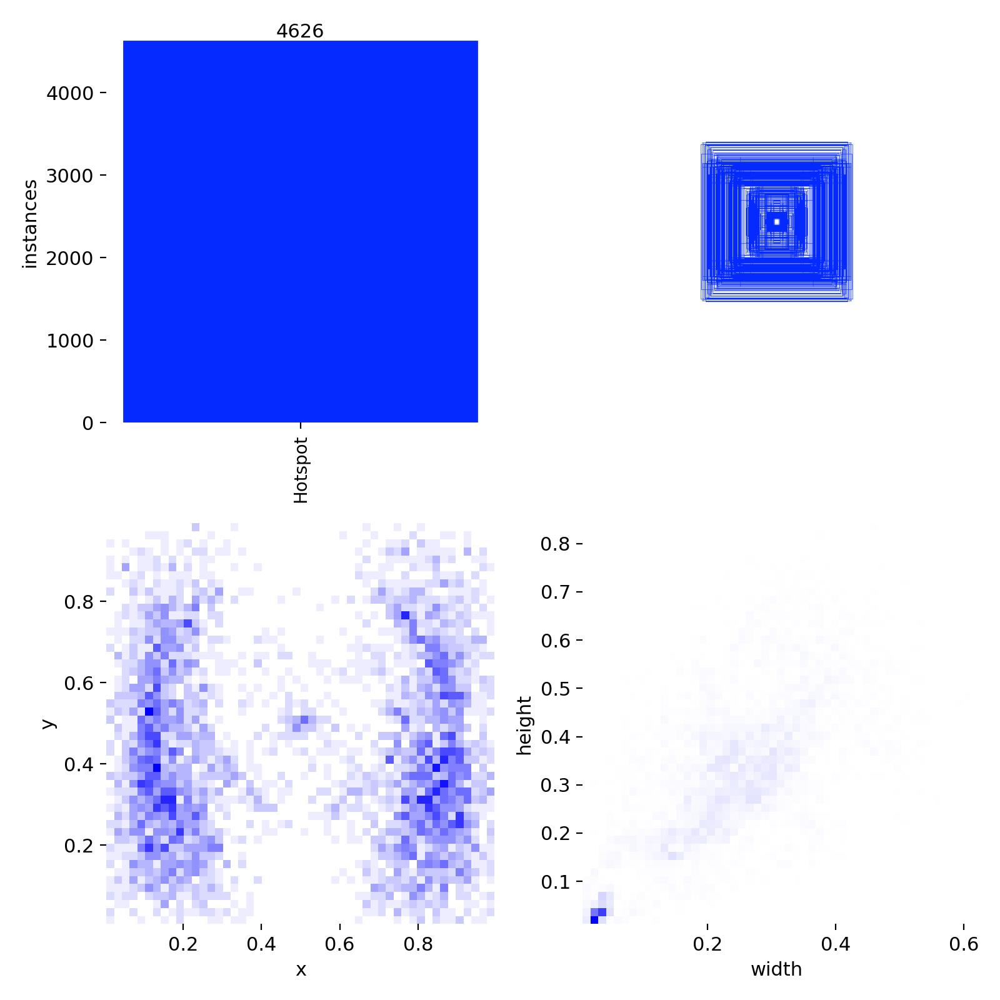

In [ ]:

import zipfile
from PIL import Image
from IPython.display import display

zip_path = "training_artifacts (1).zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    with zip_ref.open("training_artifacts/labels.jpg") as file:
        img = Image.open(file)
        display(img)


In [ ]:

import zipfile

with zipfile.ZipFile("training_artifacts (1).zip", "r") as z:
    content = z.read(
        "training_artifacts/args.yaml (Hotspot).yaml"
    ).decode("utf-8")

print(content)


task: detect
mode: train
model: yolo26s.pt
data: /content/Hotspot-1/data.yaml
epochs: 120
time: null
patience: 10
batch: 128
imgsz: 640
save: true
save_period: -1
cache: ram
device: null
workers: 16
project: null
name: train
exist_ok: false
pretrained: true
optimizer: auto
verbose: true
seed: 0
deterministic: true
single_cls: false
rect: true
cos_lr: true
close_mosaic: 10
resume: false
amp: true
fraction: 1.0
profile: false
freeze: null
multi_scale: 0.0
compile: false
overlap_mask: true
mask_ratio: 4
dropout: 0.0
val: true
split: val
save_json: false
conf: null
iou: 0.7
max_det: 300
quantize: null
dnn: false
plots: true
end2end: null
source: null
vid_stride: 1
stream_buffer: false
visualize: false
augment: false
agnostic_nms: false
classes: null
retina_masks: false
embed: null
show: false
save_frames: false
save_txt: false
save_conf: false
save_crop: false
show_labels: true
show_conf: true
show_boxes: true
line_width: null
format: torchscript
keras: false
optimize: false
dynamic: false

In [ ]:

import zipfile

with zipfile.ZipFile("training_artifacts (1).zip", "r") as z:
    content = z.read(
        "training_artifacts/args.yaml (Hotspot).yaml"
    ).decode("utf-8")

print("\n".join(content.splitlines()[:40]))


task: detect
mode: train
model: yolo26s.pt
data: /content/Hotspot-1/data.yaml
epochs: 120
time: null
patience: 10
batch: 128
imgsz: 640
save: true
save_period: -1
cache: ram
device: null
workers: 16
project: null
name: train
exist_ok: false
pretrained: true
optimizer: auto
verbose: true
seed: 0
deterministic: true
single_cls: false
rect: true
cos_lr: true
close_mosaic: 10
resume: false
amp: true
fraction: 1.0
profile: false
freeze: null
multi_scale: 0.0
compile: false
overlap_mask: true
mask_ratio: 4
dropout: 0.0
val: true
split: val
save_json: false
conf: null


In [ ]:

from google.colab import files
uploaded = files.upload()


Saving hotspot_raw_samples (1).zip to hotspot_raw_samples (1).zip


In [ ]:

import zipfile

zip_path = "hotspot_raw_samples (1).zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    files_list = zip_ref.namelist()

    print("Total files:", len(files_list))
    print("\nFirst 30 files:")

    for file in files_list[:30]:
        print(file)


Total files: 51

First 30 files:
hotspot_raw_samples/
hotspot_raw_samples/Sample_01.jpeg
hotspot_raw_samples/Sample_02.png
hotspot_raw_samples/Sample_03.png
hotspot_raw_samples/Sample_04.jpeg
hotspot_raw_samples/Sample_05.png
hotspot_raw_samples/Sample_06.png
hotspot_raw_samples/Sample_07.png
hotspot_raw_samples/Sample_08.png
hotspot_raw_samples/Sample_09.png
hotspot_raw_samples/Sample_10.png
hotspot_raw_samples/Sample_11.png
hotspot_raw_samples/Sample_12.png
hotspot_raw_samples/Sample_13.png
hotspot_raw_samples/Sample_14.png
hotspot_raw_samples/Sample_15.png
hotspot_raw_samples/Sample_16.png
hotspot_raw_samples/Sample_17.png
hotspot_raw_samples/Sample_18.png
hotspot_raw_samples/Sample_19.png
hotspot_raw_samples/Sample_20.png
hotspot_raw_samples/Sample_21.png
hotspot_raw_samples/Sample_22.png
hotspot_raw_samples/Sample_23.png
hotspot_raw_samples/Sample_24.png
hotspot_raw_samples/Sample_25.png
hotspot_raw_samples/Sample_26.png
hotspot_raw_samples/Sample_27.png
hotspot_raw_samples/Sample

In [ ]:

import zipfile
from collections import Counter
import os

zip_path = "hotspot_raw_samples (1).zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    files_list = [
        f for f in zip_ref.namelist()
        if not f.endswith('/')
    ]

    extensions = Counter(
        os.path.splitext(f)[1].lower()
        for f in files_list
    )

    print("Total files:", len(files_list))
    print("File types:", extensions)

    print("\nPossible annotation files:")
    for f in files_list:
        if f.lower().endswith(('.txt', '.yaml', '.json', '.xml')):
            print(f)


Total files: 50
File types: Counter({'.png': 48, '.jpeg': 2})

Possible annotation files:


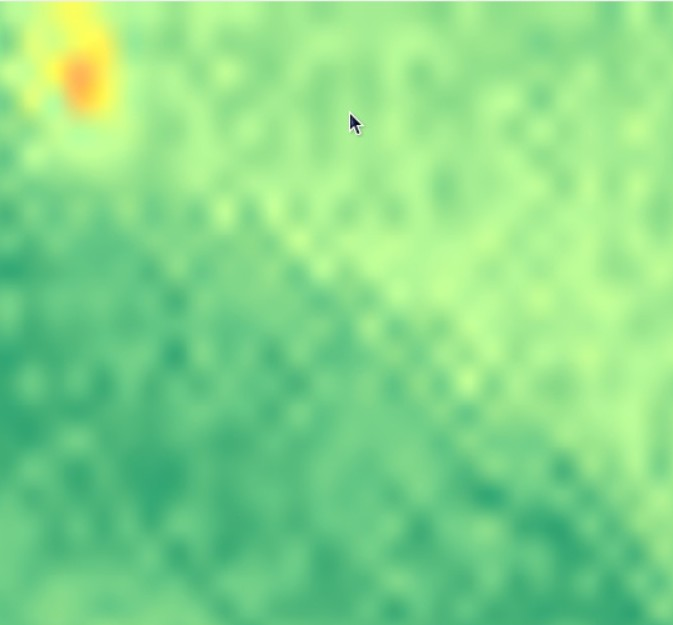

In [ ]:

import zipfile
from PIL import Image
from IPython.display import display

with zipfile.ZipFile("hotspot_raw_samples (1).zip") as z:
    image_path = "hotspot_raw_samples/Sample_01.jpeg"
    img = Image.open(z.open(image_path))
    display(img)


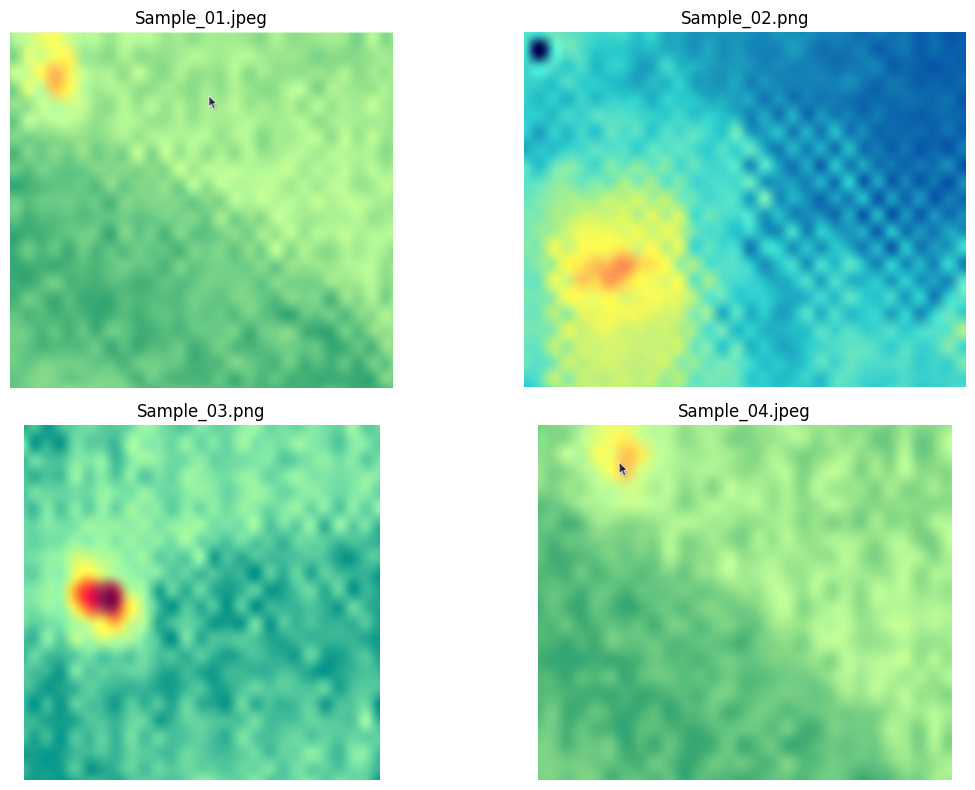

In [ ]:

import zipfile
import matplotlib.pyplot as plt
from PIL import Image

zip_path = "hotspot_raw_samples (1).zip"

with zipfile.ZipFile(zip_path, 'r') as z:
    image_files = [
        f for f in z.namelist()
        if f.lower().endswith(('.png', '.jpeg', '.jpg'))
    ]

    plt.figure(figsize=(12, 8))

    for i in range(4):
        img = Image.open(z.open(image_files[i]))

        plt.subplot(2, 2, i + 1)
        plt.imshow(img)
        plt.title(image_files[i].split('/')[-1])
        plt.axis('off')

    plt.tight_layout()
    plt.show()


In [ ]:
from pathlib import Path

base = Path("/content/drive/MyDrive")

folders = list(base.glob("Solar_Panel_Project*"))
dataset = folders[0] / "hotspot_dataset" / "hotspot_dataset_yolo"

print("Dataset folder exists:", dataset.exists())

print("\nChecking annotation files...")

label_folders = list(dataset.rglob("labels"))
yaml_files = list(dataset.rglob("*.yaml"))

print("Label folders found:", label_folders)
print("YAML files found:", yaml_files)

Dataset folder exists: True

Checking annotation files...
Label folders found: []
YAML files found: []


In [ ]:
from pathlib import Path

train_images = dataset / "train" / "images"

images = sorted([
    p for p in train_images.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

print("Training images:", len(images))
print("First 5 image names:")

for img in images[:5]:
    print(img.name)

Training images: 4000
First 5 image names:
Sample_01_aug_001.png
Sample_01_aug_002.png
Sample_01_aug_003.png
Sample_01_aug_004.png
Sample_01_aug_005.png


In [ ]:
import re

original_names = set()

for img in images:
    name = re.sub(r'_aug_\d+$', '', img.stem)
    original_names.add(name)

print("Total training images:", len(images))
print("Unique original image groups:", len(original_names))
print("\nOriginal image names:")

for name in sorted(original_names)[:15]:
    print(name)

Total training images: 4000
Unique original image groups: 40

Original image names:
Sample_01
Sample_02
Sample_03
Sample_04
Sample_07
Sample_08
Sample_11
Sample_12
Sample_13
Sample_15
Sample_16
Sample_17
Sample_18
Sample_20
Sample_21


In [ ]:
import re

original_images = [
    img for img in images
    if not re.search(r'_aug_\d+$', img.stem)
]

print("Original images found:", len(original_images))

for img in original_images[:20]:
    print(img.name)

Original images found: 0


In [ ]:
import os

for file in os.listdir("/content"):
    if "hotspot_raw_samples" in file.lower():
        print(file)

hotspot_raw_samples (1).zip


In [ ]:
import zipfile
import os

zip_path = "/content/hotspot_raw_samples (1).zip"
extract_path = "/content/hotspot_raw_samples"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")

for root, dirs, files in os.walk(extract_path):
    image_files = [
        f for f in files
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]
    if image_files:
        print("Images found:", len(image_files))
        print("Folder:", root)

Extraction completed!
Images found: 50
Folder: /content/hotspot_raw_samples/hotspot_raw_samples


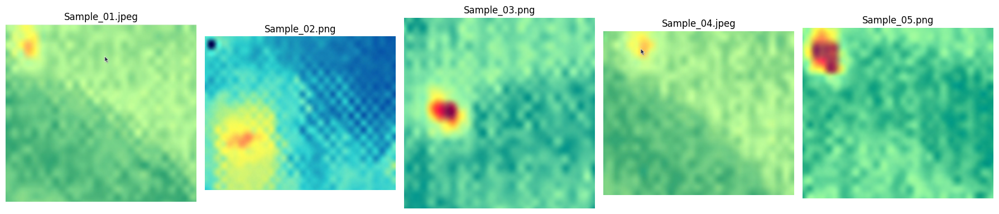

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

raw_folder = Path("/content/hotspot_raw_samples/hotspot_raw_samples")

raw_images = sorted([
    p for p in raw_folder.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for i, ax in enumerate(axes):
    img = Image.open(raw_images[i])
    ax.imshow(img)
    ax.set_title(raw_images[i].name)
    ax.axis("off")

plt.tight_layout()
plt.show()

Image: Sample_01.jpeg
Image size: (673, 625)


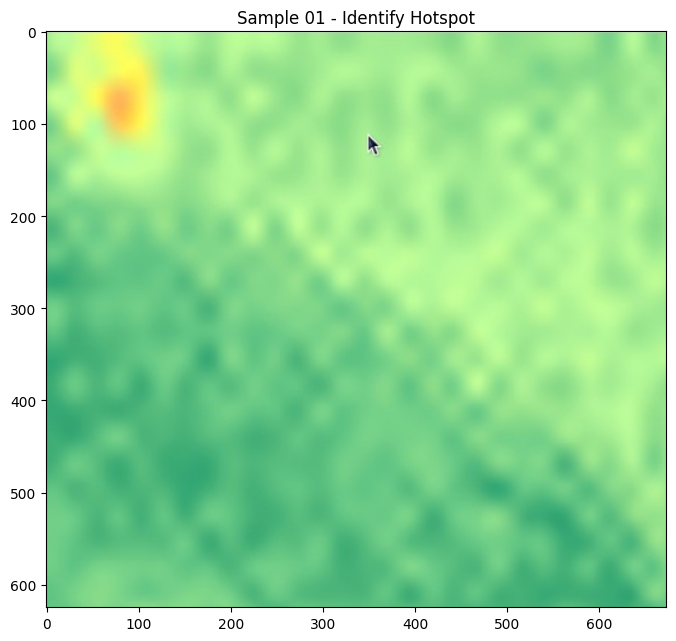

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

img_path = raw_images[0]

img = Image.open(img_path)
print("Image:", img_path.name)
print("Image size:", img.size)

plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.title("Sample 01 - Identify Hotspot")
plt.axis("on")
plt.show()

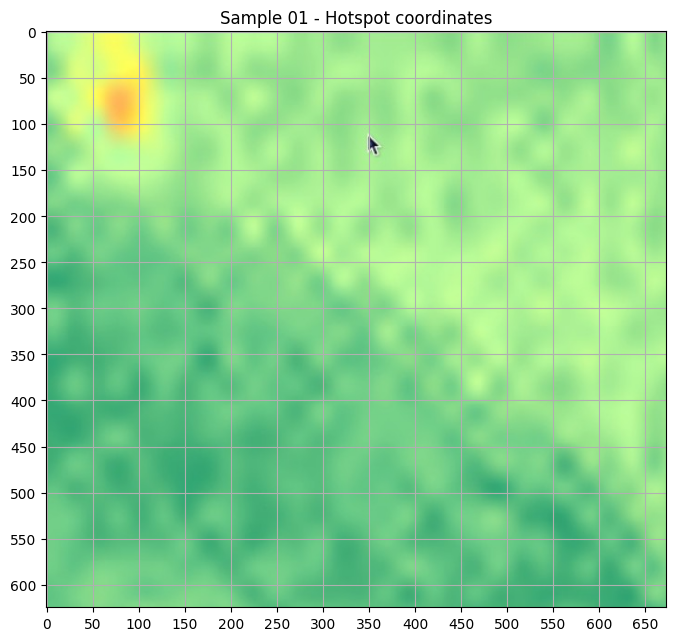

Image width: 673
Image height: 625


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

img = Image.open(raw_images[0])
width, height = img.size

plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.xticks(range(0, width, 50))
plt.yticks(range(0, height, 50))
plt.grid()
plt.title("Sample 01 - Hotspot coordinates")
plt.show()

print("Image width:", width)
print("Image height:", height)

In [ ]:
from pathlib import Path

# Create labels folder
label_folder = Path("/content/hotspot_raw_samples/labels")
label_folder.mkdir(parents=True, exist_ok=True)

# Bounding box coordinates
x_min = 48
y_min = 35
x_max = 122
y_max = 132

# Convert to YOLO format
x_center = ((x_min + x_max) / 2) / 675
y_center = ((y_min + y_max) / 2) / 625
box_width = (x_max - x_min) / 675
box_height = (y_max - y_min) / 625

# Class 0 = Hotspot
label = f"0 {x_center} {y_center} {box_width} {box_height}"

# Save annotation
label_path = label_folder / "Sample_01.txt"
label_path.write_text(label + "\n")

print("Annotation created!")
print("YOLO label:", label)
print("Saved at:", label_path)

Annotation created!
YOLO label: 0 0.1259259259259259 0.1336 0.10962962962962963 0.1552
Saved at: /content/hotspot_raw_samples/labels/Sample_01.txt


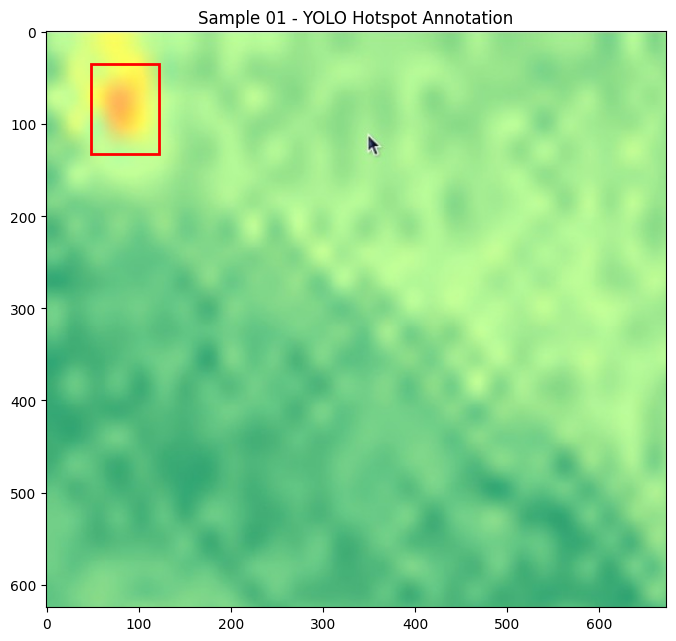

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

img = Image.open(raw_images[0])

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(img)

rect = patches.Rectangle(
    (48, 35), 74, 97,
    linewidth=2,
    edgecolor='red',
    facecolor='none'
)

ax.add_patch(rect)
ax.set_title("Sample 01 - YOLO Hotspot Annotation")
plt.show()

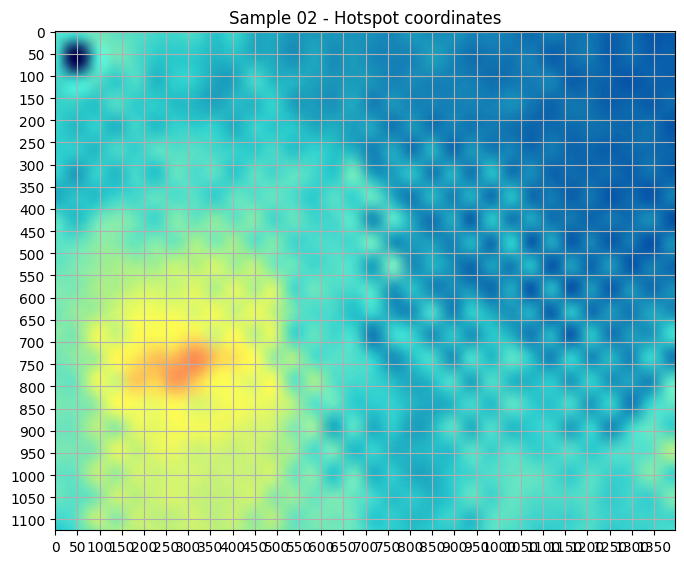

Image: Sample_02.png
Width: 1398
Height: 1125


In [ ]:
img_path = raw_images[1]

img = Image.open(img_path)
width, height = img.size

plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.xticks(range(0, width, 50))
plt.yticks(range(0, height, 50))
plt.grid()
plt.title("Sample 02 - Hotspot coordinates")
plt.show()

print("Image:", img_path.name)
print("Width:", width)
print("Height:", height)

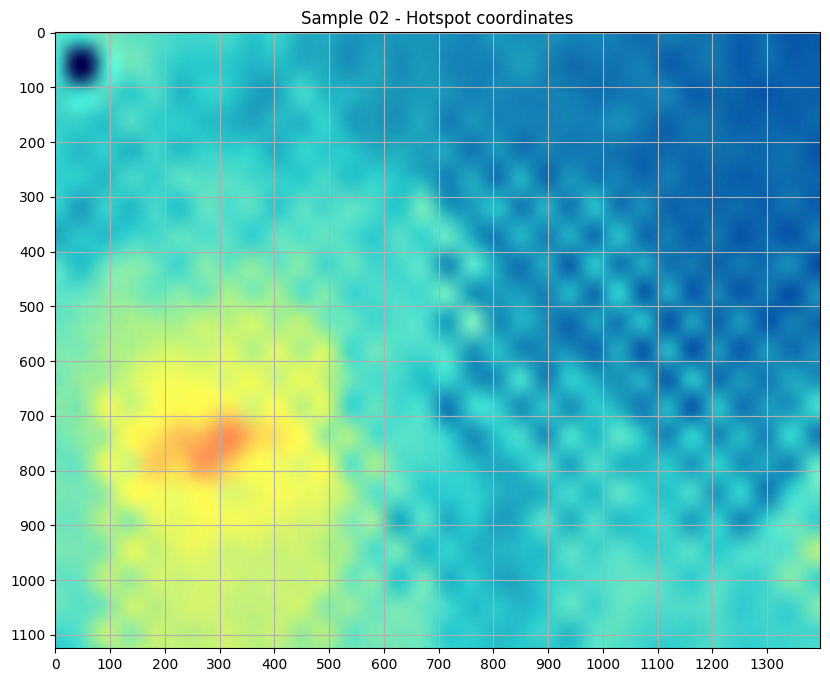

In [ ]:
img = Image.open(raw_images[1])

plt.figure(figsize=(10, 8))
plt.imshow(img)
plt.xticks(range(0, 1400, 100))
plt.yticks(range(0, 1200, 100))
plt.grid()
plt.title("Sample 02 - Hotspot coordinates")
plt.show()

In [ ]:
# Sample 02 image dimensions
width = 1398
height = 1125

# Bounding box
x_min = 70
y_min = 470
x_max = 550
y_max = 1120

# Convert to YOLO format
x_center = ((x_min + x_max) / 2) / width
y_center = ((y_min + y_max) / 2) / height
box_width = (x_max - x_min) / width
box_height = (y_max - y_min) / height

label = f"0 {x_center} {y_center} {box_width} {box_height}"

label_path = label_folder / "Sample_02.txt"
label_path.write_text(label + "\n")

print("Sample_02 annotation created!")
print("YOLO label:", label)
print("Saved at:", label_path)

Sample_02 annotation created!
YOLO label: 0 0.2217453505007153 0.7066666666666667 0.34334763948497854 0.5777777777777777
Saved at: /content/hotspot_raw_samples/labels/Sample_02.txt


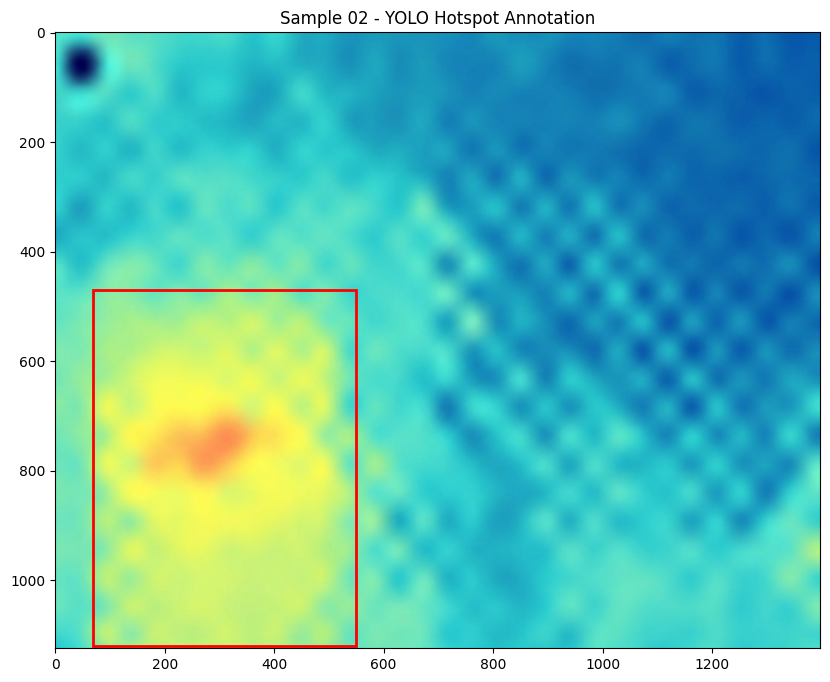

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

img = Image.open(raw_images[1])

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

rect = patches.Rectangle(
    (70, 470), 480, 650,
    linewidth=2,
    edgecolor='red',
    facecolor='none'
)

ax.add_patch(rect)
ax.set_title("Sample 02 - YOLO Hotspot Annotation")
plt.show()

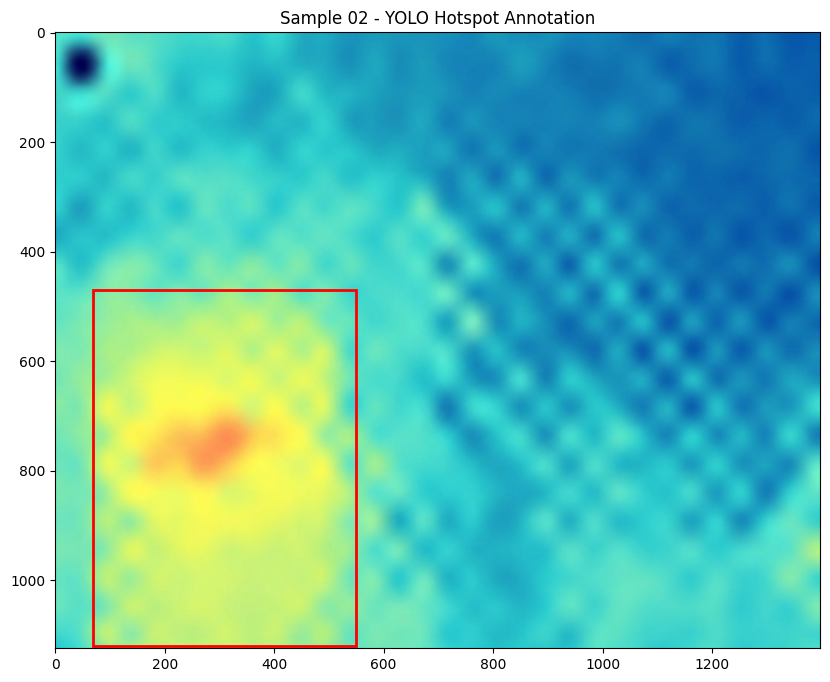

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

img = Image.open(raw_images[1])

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

rect = patches.Rectangle(
    (70, 470), 480, 650,
    linewidth=2,
    edgecolor='red',
    facecolor='none'
)

ax.add_patch(rect)
ax.set_title("Sample 02 - YOLO Hotspot Annotation")
plt.show()

In [ ]:
for folder in ["train", "valid", "test"]:
    image_folder = dataset / folder / "images"
    print(folder, ":", len(list(image_folder.glob("*"))), "images")

train : 4000 images
valid : 500 images
test : 500 images


In [ ]:
from collections import Counter

image_extensions = Counter()

for split in ["train", "valid", "test"]:
    folder = dataset / split / "images"

    for img in folder.iterdir():
        if img.is_file():
            image_extensions[img.suffix.lower()] += 1

print("Image formats:", image_extensions)

Image formats: Counter({'.png': 5000})


In [ ]:
from PIL import Image
from collections import Counter

dimensions = Counter()

for split in ["train", "valid", "test"]:
    folder = dataset / split / "images"

    for path in folder.glob("*.png"):
        with Image.open(path) as img:
            dimensions[img.size] += 1

print("Image dimensions:")
for size, count in dimensions.items():
    print(size, ":", count, "images")

Image dimensions:
(640, 640) : 5000 images


In [ ]:
for split in ["train", "valid", "test"]:
    label_folder = dataset / split / "labels"

    if label_folder.exists():
        count = len(list(label_folder.glob("*.txt")))
    else:
        count = 0

    print(split, "labels:", count)

train labels: 0
valid labels: 0
test labels: 0


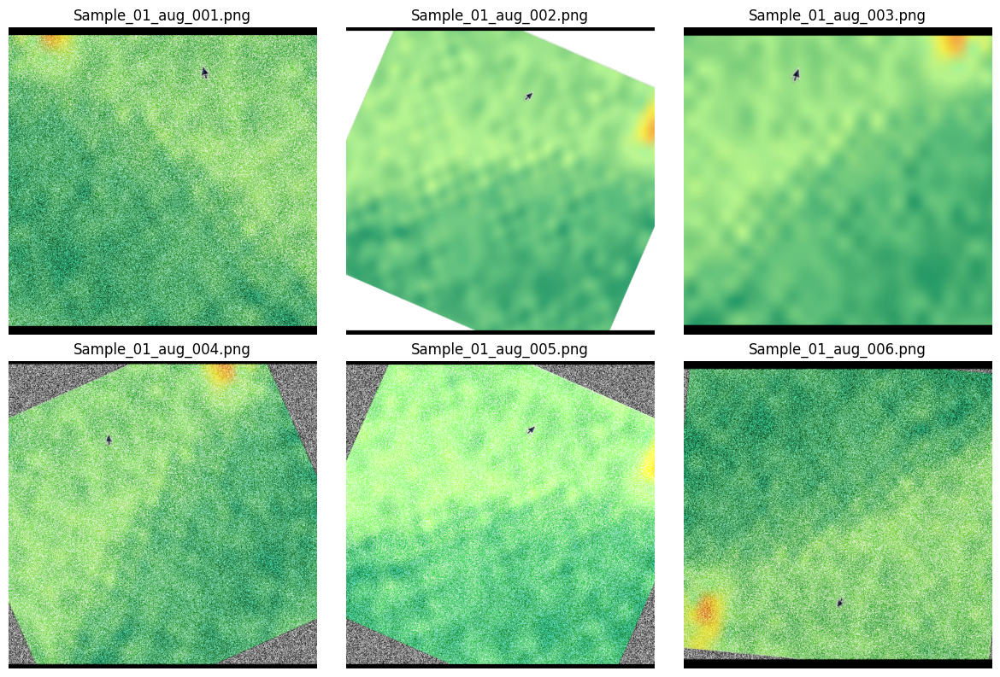

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

sample_images = sorted((dataset / "train" / "images").glob("*.png"))[:6]

for ax, path in zip(axes.flat, sample_images):
    img = Image.open(path)
    ax.imshow(img)
    ax.set_title(path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()

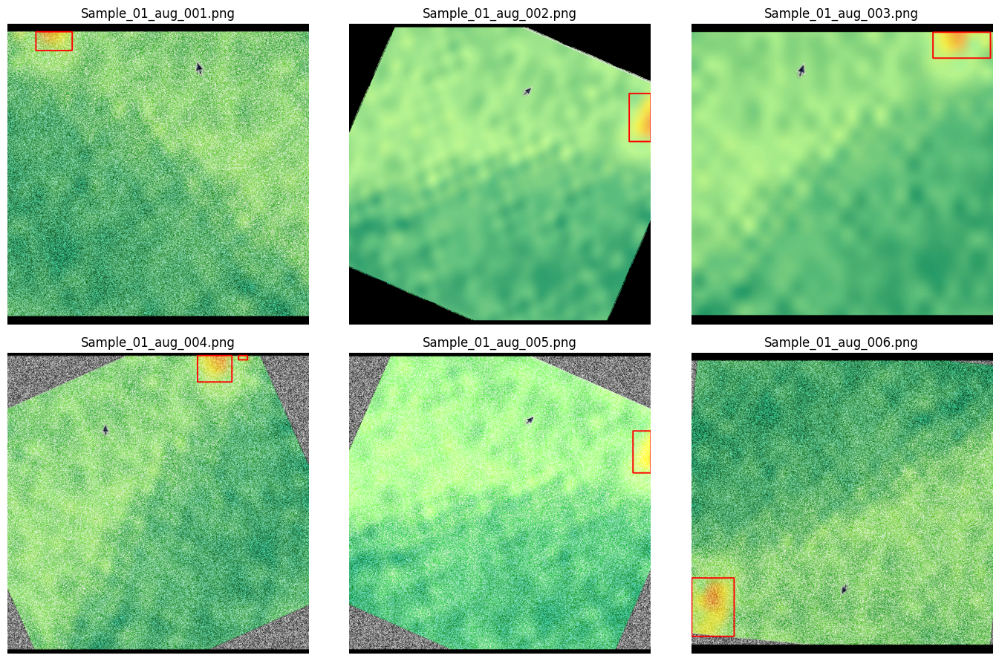

In [ ]:
import cv2
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for ax, path in zip(axes.flat, sample_images):
    img = cv2.imread(str(path))
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    # Candidate yellow/orange regions
    lower = np.array([5, 80, 100])
    upper = np.array([40, 255, 255])

    mask = cv2.inRange(hsv, lower, upper)

    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    for contour in contours:
        if cv2.contourArea(contour) > 30:
            x, y, w, h = cv2.boundingRect(contour)
            cv2.rectangle(img, (x, y), (x+w, y+h), (0, 0, 255), 2)

    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import cv2
import numpy as np
from pathlib import Path

total = 0
total_boxes = 0

for split in ["train", "valid", "test"]:

    image_folder = dataset / split / "images"
    label_folder = dataset / split / "labels"
    label_folder.mkdir(parents=True, exist_ok=True)

    for path in image_folder.glob("*.png"):

        img = cv2.imread(str(path))
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

        lower = np.array([5, 80, 100])
        upper = np.array([40, 255, 255])

        mask = cv2.inRange(hsv, lower, upper)

        kernel = np.ones((3, 3), np.uint8)
        mask = cv2.morphologyEx(
            mask, cv2.MORPH_OPEN, kernel
        )

        contours, _ = cv2.findContours(
            mask, cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE
        )

        labels = []
        h, w = img.shape[:2]

        for contour in contours:
            if cv2.contourArea(contour) < 40:
                continue

            x, y, bw, bh = cv2.boundingRect(contour)

            xc = (x + bw / 2) / w
            yc = (y + bh / 2) / h
            nw = bw / w
            nh = bh / h

            labels.append(
                f"0 {xc:.6f} {yc:.6f} {nw:.6f} {nh:.6f}"
            )

        (label_folder / f"{path.stem}.txt").write_text(
            "\n".join(labels)
        )

        total += 1
        total_boxes += len(labels)

print("Images processed:", total)
print("Candidate hotspot boxes:", total_boxes)
print("YOLO label files created!")

Images processed: 5000
Candidate hotspot boxes: 9505
YOLO label files created!


In [ ]:
import yaml

data_config = {
    "path": str(dataset),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": {
        0: "hotspot"
    }
}

yaml_path = dataset / "data.yaml"

with open(yaml_path, "w") as f:
    yaml.dump(data_config, f, sort_keys=False)

print("YOLO configuration created!")
print(yaml_path)

YOLO configuration created!
/content/drive/MyDrive/Solar_Panel_Project./hotspot_dataset/hotspot_dataset_yolo/data.yaml


In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Please enable GPU in Runtime > Change runtime type > T4 GPU")

GPU available: True
GPU: Tesla T4


In [ ]:
!pip install -q ultralytics

from ultralytics import YOLO

# Load a lightweight YOLO model
model = YOLO("yolov8n.pt")

# Start training
results = model.train(
    data=str(yaml_path),
    epochs=30,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    patience=10,
    project="/content/drive/MyDrive/Solar_Panel_Project./training_results",
    name="hotspot_detection"
)

print("YOLO training completed!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Solar_Panel_Project./hotspot_dataset/hotspot_dataset_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=Fals

In [ ]:
from pathlib import Path
import pandas as pd

results_folder = Path(
    "/content/drive/MyDrive/Solar_Panel_Project./training_results/hotspot_detection"
)

print("Training folder exists:", results_folder.exists())

csv_file = results_folder / "results.csv"

if csv_file.exists():
    df = pd.read_csv(csv_file)
    print("Epochs completed:", len(df))
    display(df.tail(3))

weights = results_folder / "weights"

if weights.exists():
    print("Saved model files:")
    for file in weights.iterdir():
        print(file.name)
else:
    print("Weights folder not found")

Training folder exists: False
Weights folder not found


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

project_path = "/content/drive/MyDrive/Solar_Panel_Project."

print("Project folder exists:", os.path.exists(project_path))

if os.path.exists(project_path):
    print("Folders inside project:")
    print(os.listdir(project_path))

Mounted at /content/drive
Project folder exists: True
Folders inside project:
['hotspot_dataset', 'training_results']


In [ ]:
import os

results_path = "/content/drive/MyDrive/Solar_Panel_Project./training_results"

for root, dirs, files in os.walk(results_path):
    print("\nFolder:", root)
    print("Subfolders:", dirs)
    print("Files:", files[:15])


Folder: /content/drive/MyDrive/Solar_Panel_Project./training_results
Subfolders: ['hotspot_detection']
Files: []

Folder: /content/drive/MyDrive/Solar_Panel_Project./training_results/hotspot_detection
Subfolders: ['weights']
Files: ['args.yaml', 'labels.jpg', 'train_batch0.jpg', 'train_batch1.jpg', 'train_batch2.jpg', 'results.csv']

Folder: /content/drive/MyDrive/Solar_Panel_Project./training_results/hotspot_detection/weights
Subfolders: []
Files: ['best.pt', 'last.pt']


In [ ]:
import pandas as pd

csv_path = "/content/drive/MyDrive/Solar_Panel_Project./training_results/hotspot_detection/results.csv"

df = pd.read_csv(csv_path)

print("Completed epochs:", len(df))
print("\nLast training results:")
print(df.tail(3).to_string(index=False))

Completed epochs: 17

Last training results:
 epoch    time  train/box_loss  train/cls_loss  train/dfl_loss  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)  val/box_loss  val/cls_loss  val/dfl_loss   lr/pg0   lr/pg1   lr/pg2
    15 1745.30         0.69422         0.46315         0.98523               0.56654            0.48286           0.50994              0.31215       1.02050       0.72875       0.89935 0.001076 0.001076 0.001076
    16 1861.02         0.67029         0.45028         0.97539               0.59695            0.50124           0.57585              0.37079       0.87296       0.66953       0.85361 0.001010 0.001010 0.001010
    17 1978.19         0.67166         0.44421         0.97689               0.53540            0.45156           0.46139              0.29739       0.99266       0.71303       0.89541 0.000944 0.000944 0.000944


In [ ]:
from ultralytics import YOLO

last_model_path = "/content/drive/MyDrive/Solar_Panel_Project./training_results/hotspot_detection/weights/last.pt"

model = YOLO(last_model_path)

results = model.train(resume=True)

print("YOLO training completed!")

ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
!pip install -q ultralytics

In [ ]:
from ultralytics import YOLO

last_model_path = "/content/drive/MyDrive/Solar_Panel_Project./training_results/hotspot_detection/weights/last.pt"

model = YOLO(last_model_path)

results = model.train(resume=True)

print("YOLO training completed!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.210 🚀 Python-3.13.18 torch-2.14.1+cpu 


ValueError: Invalid CUDA 'device=0' requested. Use 'device=cpu' or pass valid CUDA device(s) if available, i.e. 'device=0' or 'device=0,1,2,3' for Multi-GPU.

torch.cuda.is_available(): False
torch.cuda.device_count(): 0
os.environ['CUDA_VISIBLE_DEVICES']: None
See https://pytorch.org/get-started/locally/ for up-to-date torch install instructions if no CUDA devices are seen by torch.


In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

GPU available: False


In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

GPU available: False


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

model_folder = "/content/drive/MyDrive/Solar_Panel_Project./training_results/hotspot_detection/weights"

print("Files available:")
print(os.listdir(model_folder))

Files available:
['best.pt', 'last.pt']


In [3]:
!pip install -q ultralytics

from ultralytics import YOLO
from pathlib import Path
import matplotlib.pyplot as plt

# Load saved model
model_path = "/content/drive/MyDrive/Solar_Panel_Project./training_results/hotspot_detection/weights/best.pt"

model = YOLO(model_path)

print("YOLO model loaded successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLO model loaded successfully!


In [4]:
dataset = Path("/content/drive/MyDrive/Solar_Panel_Project./hotspot_dataset/hotspot_dataset_yolo")

test_images = sorted((dataset / "test" / "images").glob("*.png"))

print("Total test images:", len(test_images))
print("First test image:", test_images[0])

Total test images: 500
First test image: /content/drive/MyDrive/Solar_Panel_Project./hotspot_dataset/hotspot_dataset_yolo/test/images/Sample_09_aug_001.png


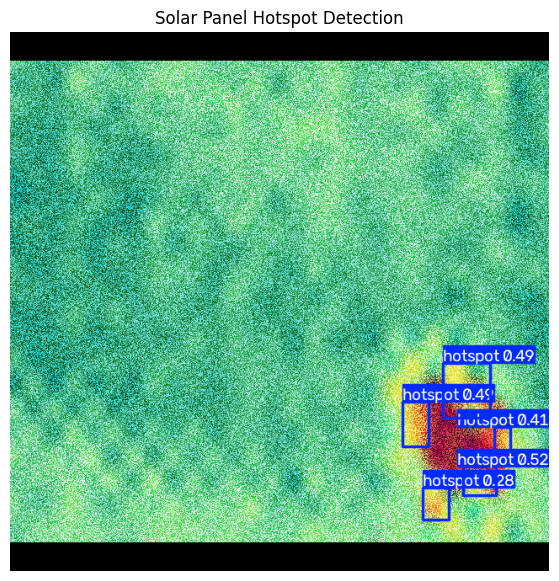

Prediction completed!
Detected hotspots: 5


In [5]:
import matplotlib.pyplot as plt

# Predict hotspot on the first test image
result = model.predict(
    source=str(test_images[0]),
    conf=0.25,
    verbose=False
)[0]

# Display prediction
plt.figure(figsize=(9, 7))
plt.imshow(result.plot()[..., ::-1])
plt.title("Solar Panel Hotspot Detection")
plt.axis("off")
plt.show()

print("Prediction completed!")
print("Detected hotspots:", len(result.boxes))

In [6]:
output_folder = "/content/drive/MyDrive/Solar_Panel_Project./Final_Results"
import os
os.makedirs(output_folder, exist_ok=True)

result.save(filename=output_folder + "/hotspot_prediction.png")

print("Prediction image saved successfully!")
print(output_folder)

Prediction image saved successfully!
/content/drive/MyDrive/Solar_Panel_Project./Final_Results


In [7]:
from pathlib import Path
from ultralytics import YOLO

output_folder = Path("/content/drive/MyDrive/Solar_Panel_Project./Final_Results")
prediction_folder = output_folder / "All_Predictions"
prediction_folder.mkdir(parents=True, exist_ok=True)

model.predict(
    source=str(dataset / "test" / "images"),
    conf=0.25,
    save=True,
    project=str(output_folder),
    name="All_Predictions",
    exist_ok=True,
    verbose=False
)

print("All test image predictions completed!")
print("Saved in:", prediction_folder)

Results saved to /content/drive/MyDrive/Solar_Panel_Project./Final_Results/All_Predictions
All test image predictions completed!
Saved in: /content/drive/MyDrive/Solar_Panel_Project./Final_Results/All_Predictions


In [8]:
import os
import shutil
import zipfile
import pandas as pd
from pathlib import Path

base = Path("/content/drive/MyDrive/Solar_Panel_Project.")
results = base / "training_results/hotspot_detection"
weights = results / "weights"
final = base / "Final_Results"
predictions = final / "All_Predictions"

# Create submission folder
submission = base / "Submission_Package"
submission.mkdir(exist_ok=True)

# Copy important files
shutil.copy(weights / "best.pt", submission / "best.pt")
shutil.copy(results / "results.csv", submission / "training_results.csv")

yaml_file = base / "hotspot_dataset/hotspot_dataset_yolo/data.yaml"
shutil.copy(yaml_file, submission / "data.yaml")

prediction_image = final / "hotspot_prediction.png"
if prediction_image.exists():
    shutil.copy(prediction_image, submission / "sample_prediction.png")

# Read training metrics
df = pd.read_csv(results / "results.csv")
df.columns = df.columns.str.strip()

metric_columns = [
    "metrics/precision(B)",
    "metrics/recall(B)",
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)"
]

available = [c for c in metric_columns if c in df.columns]
best_row = df.loc[df[available[-1]].idxmax()] if available else None

metrics_text = ""
if best_row is not None:
    metrics_text = "\n".join(
        f"{c}: {best_row[c]:.4f}" for c in available
    )

# Create report
report = f"""
SOLAR PANEL HOTSPOT DETECTION USING YOLO

1. INTRODUCTION
Solar panels can develop hotspots due to faults, shading,
damaged cells and other operating conditions. This project
uses a YOLO object detection model to identify candidate
hotspot regions in solar panel thermal images.

2. OBJECTIVE
To develop a prototype object detection system that processes
solar panel images and highlights candidate hotspot regions.

3. TECHNOLOGIES USED
- Python
- Google Colab
- YOLOv8
- Ultralytics
- PyTorch
- OpenCV
- Matplotlib

4. DATASET
- Total images: 5000
- Training images: 4000
- Validation images: 500
- Testing images: 500

5. METHODOLOGY
1. Dataset extraction and inspection.
2. Automatic candidate-region annotation using HSV colour
   thresholding.
3. Preparation of YOLO-format labels and data.yaml.
4. YOLOv8n model training.
5. Model prediction on test images.
6. Saving prediction images.

6. TRAINING
Training was interrupted after 17 epochs because of the
Google Colab GPU usage limit. The saved best model checkpoint
was used to generate predictions on all 500 test images.

7. TRAINING METRICS
{metrics_text}

8. RESULTS
The saved YOLO model processed all 500 test images.
Prediction images are available in the Final_Results folder.

9. LIMITATIONS
The labels were automatically generated using thermal colour
thresholding. They are provisional candidate annotations,
not independently verified ground-truth labels. Therefore,
the reported metrics and predictions are preliminary and
should not be treated as validated real-world accuracy.

10. CONCLUSION
A YOLOv8-based solar panel hotspot detection prototype was
implemented. The model was trained, saved and used to generate
predictions for the test images. Further work should include
expert-verified annotations and independent model evaluation.
"""

(submission / "Project_Report.txt").write_text(report)

readme = """
# Solar Panel Hotspot Detection using YOLO

## Project
A prototype for detecting candidate hotspot regions in solar
panel thermal images using YOLOv8n.

## Technologies
Python, Google Colab, YOLOv8, Ultralytics, PyTorch, OpenCV.

## Dataset
5000 images:
- Train: 4000
- Validation: 500
- Test: 500

## Files
- best.pt: saved YOLO model
- training_results.csv: training metrics
- data.yaml: YOLO dataset configuration
- sample_prediction.png: sample output
- Project_Report.txt: project report

## Important limitation
Labels were generated using automatic HSV colour thresholding.
They are provisional and require expert verification.
The model is a prototype, not a validated diagnostic system.
"""

(submission / "README.md").write_text(readme)

# Create ZIP
zip_path = base / "Solar_Panel_Hotspot_Submission.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in submission.rglob("*"):
        if file.is_file():
            z.write(file, file.relative_to(submission))

print("SUBMISSION PACKAGE CREATED!")
print("Folder:", submission)
print("ZIP:", zip_path)
print("Files:", os.listdir(submission))
print("Prediction images generated:", len(list(predictions.glob("*.png"))))

SUBMISSION PACKAGE CREATED!
Folder: /content/drive/MyDrive/Solar_Panel_Project./Submission_Package
ZIP: /content/drive/MyDrive/Solar_Panel_Project./Solar_Panel_Hotspot_Submission.zip
Files: ['best.pt', 'training_results.csv', 'data.yaml', 'sample_prediction.png', 'Project_Report.txt', 'README.md']
Prediction images generated: 0


In [9]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/Solar_Panel_Project./Solar_Panel_Hotspot_Submission.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>